# BIOT 6900 · Module 9 — Notebook 3 (GRADED)
## Clinical NLP on your own disease: build it, then catch the leakage
**Week 9 · Part III · this is the graded assignment**

> **⚠️ SYNTHETIC.** You design a synthetic patient population for a disease of your choice, run the full pipeline on it, and then do the hard part: look at what the model learned and separate genuine early signal from leakage.

You configure your disease's clinical picture (which findings are genuine early signals, which are interventions done to deteriorating patients). The notebook builds a cohort and notes from your choices, extracts features, trains a model, and reports permutation importance. **It also injects two clinical features you did not configure** — you must diagnose each as signal or leakage from the output.

**What is graded (course 60 / 40):** 60% execution (your config is clinically sensible, the notebook runs, the pipeline is correct) and **40% interpretation** (Part D: correctly sorting signal from leakage and defending it). See the assignment sheet for the rubric.

**How to run:** `Kernel → Restart & Run All`. It uses only `pandas` + `scikit-learn`.

## The engine (provided, do not edit)
Run this cell and move on. It defines the assertion engine, the cohort/notes generator, and the model helpers.

In [1]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# --- ConText assertion engine (from Notebook 2) ---
NEG_PRE  = ["no evidence of", "no acute", "denies", "denied", "without", "negative for", "ruled out for", "r/o", "no "]
NEG_POST = ["ruled out", "was negative", "is negative", "unlikely", "resolved"]
PSEUDO   = ["no change", "no increase", "no further", "not only", "cannot be ruled out", "gram negative"]
FAM      = ["mother", "father", "sister", "brother", "parent", "family history", "fh "]
HIST     = ["history of", "h/o", "hx of", "prior", "previous", "status post", "s/p", "chronic"]
HYPO     = ["if ", "would ", "should ", "to prevent", "risk of", "monitor for"]
def _sents(t): return [s.strip() for s in re.split(r"[.;\n]", t) if s.strip()]
def assertion(term, text):
    for sent in _sents(text):
        low = sent.lower()
        m = re.search(r"\b" + re.escape(term.lower()) + r"\b", low)
        if not m: continue
        pos = m.start(); pseudo = any(p in low for p in PSEUDO)
        pre = low[max(0, pos-60):pos]; post = low[pos+len(term):pos+len(term)+45]
        if any(x in low for x in FAM): return "family"
        if any(x in pre for x in HYPO): return "hypothetical"
        if not pseudo and (any(x in pre for x in NEG_PRE) or any(x in post for x in NEG_POST)): return "absent"
        if any(x in pre for x in HIST): return "historical"
        return "present"
    return None

def concept_present(synonyms, note_texts):
    for v in synonyms:
        for t in note_texts:
            if assertion(v, t) == "present":
                return 1
    return 0

# two features injected that you did NOT configure (diagnose them in Part D):
WILDCARDS = {
    "lactate_not_clearing": ["failing to clear", "not clearing"],
    "renal_replacement":    ["dialysis", "renal replacement therapy"],
}

def build_world(cfg, seed=2024, N=400):
    rng = np.random.default_rng(seed)
    age = rng.integers(40, 92, N); sex = rng.choice(["M", "F"], N)
    lactate = rng.normal(2.2, 1.3, N).clip(0.5, 14); creatinine = rng.normal(1.1, 0.6, N).clip(0.3, 9)
    sig_names = list(cfg["signals"]); con_names = list(cfg["consequences"])
    sig_present = {s: rng.random(N) < rng.uniform(0.18, 0.30) for s in sig_names}
    w_sig = rng.random(N) < 0.22                               # wildcard SIGNAL (a cause)
    logit = -2.3 + 0.045*(age-65) + 0.55*(lactate-2) + 0.3*(creatinine-1) + 0.55*w_sig
    for s in sig_names: logit = logit + 0.6*sig_present[s]
    died = (rng.random(N) < 1/(1+np.exp(-logit))).astype(int)
    w_leak = ((died == 1) & (rng.random(N) < 0.5)) | ((died == 0) & (rng.random(N) < 0.10))  # wildcard LEAK

    def notes_for(i):
        adm = [f"{age[i]}{sex[i]} admitted to the ICU.", f"Lactate {lactate[i]:.1f}, creatinine {creatinine[i]:.1f}."]
        for s in sig_names:
            syns = cfg["signals"][s]
            if sig_present[s][i]: adm.append(f"Clinical note: {rng.choice(syns)} present.")
            elif rng.random() < 0.25: adm.append(f"No evidence of {syns[0]}.")
        if w_sig[i]: adm.append("Lactate failing to clear despite resuscitation.")
        if rng.random() < 0.2: adm.append("History of MI, no acute chest pain.")
        prog = ["Progress note, hospital day 2."]
        if rng.random() < 0.15: prog.append("Family history of diabetes.")
        disch = ["Discharge / final note."]
        if died[i]:
            for c in con_names:
                if rng.random() < 0.5: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Required renal replacement therapy (dialysis).")
        else:
            for c in con_names:
                if rng.random() < 0.10: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Brief dialysis for contrast, since stopped.")
            disch.append(rng.choice(["Tolerating diet, ambulating.", "Stable for discharge."]))
        return [" ".join(adm), " ".join(prog), " ".join(disch)]

    NOTES = [notes_for(i) for i in range(N)]
    struct = pd.DataFrame({"subject_id": np.arange(1, N+1), "age": age, "sex": sex,
                           "lactate": lactate.round(1), "creatinine": creatinine.round(1), "died": died})
    struct.loc[rng.random(N) < 0.15, "lactate"] = np.nan
    return struct, NOTES

def cv_auroc(df, cols):
    X, y = df[cols].values, df["died"].values
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
    s = cross_val_score(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    return s.mean(), s.std()

def perm_importance(df, cols):
    X, y = df[cols].values, df["died"].values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    pi = permutation_importance(pipe, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=0)
    return pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)

print("engine loaded.")

engine loaded.


## Part A — Configure your disease  (TODO)
Replace the EXAMPLE config with **your own disease**. You need:
- 2–3 **signals**: genuine, *early* findings that are **causes** of deterioration (present before things go wrong).
- 2–3 **consequences**: interventions or actions taken *because* a patient is deteriorating. These are your planted leakage.
- For each, give a few **synonyms / abbreviations** (the notes will use them at random, so normalization matters).

Choosing these well is a clinical-reasoning task, and it is graded. A cause belongs in `signals`; a treatment or end-of-life decision belongs in `consequences`.

In [2]:
# ======== EDIT THIS: replace the example with YOUR disease ========
CONFIG = {
    "disease": "Diabetic ketoacidosis (DKA)",
    "signals": {                     # genuine EARLY findings that CAUSE deterioration
        "severe_acidosis":         ["severe acidosis", "severe metabolic acidosis",
                                    "profound acidemia", "refractory acidosis"],
        "altered_mental_status":   ["altered mental status", "ams", "obtundation", "encephalopathy"],
        "precipitating_infection": ["precipitating infection", "urosepsis", "pneumonia", "bacteremia"],
    },
    "consequences": {                # interventions done BECAUSE a patient is deteriorating (LEAKAGE)
        "pressors":     ["pressors", "norepinephrine", "levophed", "vasopressors"],
        "intubation":   ["intubated", "mechanical ventilation", "on the vent"],
        "comfort_care": ["comfort care", "cmo", "hospice"],
    },
}

SEED = 2020300       # my student ID (002020300)
# =================================================================

struct, NOTES = build_world(CONFIG, seed=SEED, N=400)
print("#"*70)
print(f"# SYNTHETIC cohort for: {CONFIG['disease']}")
print(f"# 400 patients, 3 notes each. Mortality prevalence = {struct.died.mean():.2f}")
print("#"*70)
print("Example patient notes:")
for tag, t in zip(["admit ", "day 2 ", "final "], NOTES[0]):
    print(f"  [{tag}] {t}")

######################################################################
# SYNTHETIC cohort for: Diabetic ketoacidosis (DKA)
# 400 patients, 3 notes each. Mortality prevalence = 0.23
######################################################################
Example patient notes:
  [admit ] 57M admitted to the ICU. Lactate 1.4, creatinine 0.3. Clinical note: obtundation present.
  [day 2 ] Progress note, hospital day 2.
  [final ] Discharge / final note. On the vent. Stable for discharge.


## Part B — Extract features  (TODO)
Assemble every concept to extract: your signals, your consequences, and the two injected wildcards. Then run the extractor across all 400 patients.

In [3]:
# the two injected features you did NOT configure are added here for you:
ALL_CONCEPTS = {**CONFIG["signals"], **CONFIG["consequences"], **WILDCARDS}

feat = pd.DataFrame({"subject_id": struct.subject_id})
for name, syns in ALL_CONCEPTS.items():
    feat[name] = [concept_present(syns, NOTES[i]) for i in range(400)]

print("Patients with each concept asserted PRESENT:")
print(feat.drop(columns="subject_id").sum().to_string())

Patients with each concept asserted PRESENT:
severe_acidosis            132
altered_mental_status      100
precipitating_infection     84
pressors                    81
intubation                  82
comfort_care                69
lactate_not_clearing        78
renal_replacement           87


Sanity check: compare naive keyword counting to assertion-aware counting for one of your signals.

In [4]:
one_signal = list(CONFIG["signals"])[0]
syns = CONFIG["signals"][one_signal]
naive = sum(int(any(re.search(r"\b"+re.escape(v)+r"\b", " ".join(NOTES[i]), re.I) for v in syns)) for i in range(400))
aware = int(feat[one_signal].sum())
print(f"{one_signal}:  naive keyword count = {naive}   assertion-aware = {aware}")

severe_acidosis:  naive keyword count = 206   assertion-aware = 132


## Part C — Model and importance  (TODO)
Build the feature matrix, then **declare which of YOUR concepts you planted as leakage**. Do not include the wildcards yet — you have to find those in Part D.

In [5]:
df = struct.merge(feat, on="subject_id")
df["sex_F"] = (df.sex == "F").astype(int)
struct_cols = ["age", "sex_F", "lactate", "creatinine"]
concept_cols = list(ALL_CONCEPTS)
all_cols = struct_cols + concept_cols

# TODO: list the concepts YOU configured as consequences (your planted leakage)
declared_leak = list(CONFIG["consequences"])     # EDIT if you want; by default your consequences

m, sd   = cv_auroc(df, all_cols)
mh, sdh = cv_auroc(df, [c for c in all_cols if c not in declared_leak])
print(f"CV AUROC   all features = {m:.3f} ± {sd:.3f}")
print(f"CV AUROC   your declared leakage removed = {mh:.3f} ± {sdh:.3f}")

CV AUROC   all features = 0.929 ± 0.016
CV AUROC   your declared leakage removed = 0.858 ± 0.027


renal_replacement          0.111
comfort_care               0.048
pressors                   0.034
intubation                 0.032
age                        0.016
lactate                    0.007
severe_acidosis            0.005
lactate_not_clearing       0.003
altered_mental_status      0.001
precipitating_infection   -0.000
sex_F                     -0.001
creatinine                -0.009


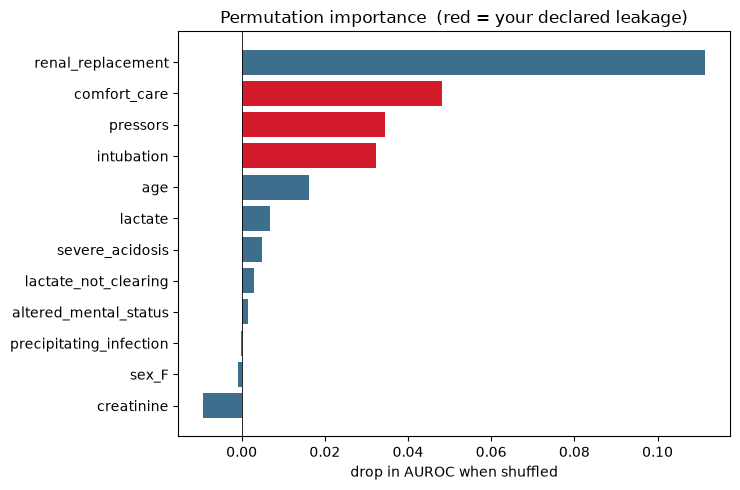

In [6]:
imp = perm_importance(df, all_cols)
print(imp.round(3).to_string())

order = imp.sort_values()
leakset = set(declared_leak)
colors = ["#D41B2C" if c in leakset else "#3E6E8E" for c in order.index]
plt.figure(figsize=(7.5, 5))
plt.barh(order.index, order.values, color=colors)
plt.axvline(0, color="black", linewidth=0.6)
plt.title("Permutation importance  (red = your declared leakage)")
plt.xlabel("drop in AUROC when shuffled"); plt.tight_layout(); plt.show()

In [7]:
# Extra check (my own addition, used as evidence in D2): WHEN is each concept documented,
# and how lopsided is it by outcome? A genuine early signal should appear in the ADMIT note and
# be only mildly enriched in the patients who died. Leakage appears in the FINAL note and is
# heavily enriched, because it was done BECAUSE the patient was deteriorating.
rows = []
for name, syns in ALL_CONCEPTS.items():
    where = [sum(int(any(re.search(r"\b"+re.escape(v)+r"\b", NOTES[i][k], re.I) for v in syns))
                 for i in range(400)) for k in range(3)]
    d = 100 * df.loc[df.died == 1, name].mean()
    s = 100 * df.loc[df.died == 0, name].mean()
    rows.append({"concept": name, "admit": where[0], "day2": where[1], "final": where[2],
                 "%died": round(d, 1), "%survived": round(s, 1), "ratio": round(d / max(s, 0.01), 1)})
timing = pd.DataFrame(rows).set_index("concept")
print("Documentation timing and outcome enrichment:")
print(timing.to_string())


Documentation timing and outcome enrichment:
                         admit  day2  final  %died  %survived  ratio
concept                                                             
severe_acidosis            206     0      0   35.5       32.2    1.1
altered_mental_status      180     0      0   33.3       22.5    1.5
precipitating_infection    161     0      0   25.8       19.5    1.3
pressors                     0     0     81   52.7       10.4    5.1
intubation                   0     0     82   46.2       12.7    3.6
comfort_care                 0     0     69   46.2        8.5    5.5
lactate_not_clearing        78     0      0   22.6       18.6    1.2
renal_replacement            0     0     87   59.1       10.4    5.7


## Part D — Catch the leakage and interpret  (GRADED, the 40%)
Now the real work. Answer each prompt in the markdown cell that follows it. Use the permutation importance and the AUROC numbers as evidence, and clinical reasoning (cause vs consequence) as the argument.

### D1. Read the importance plot
List the features at the **top** of the permutation-importance ranking. For each, say whether it is genuine early **signal** or **leakage**, and give a one-sentence clinical reason (is it a cause the patient had, or a consequence of them deteriorating?).

> *Your answer:*
>
> The ranking is dominated by four features, and **all four are leakage**:
>
> | Rank | Feature | Importance | Verdict | Clinical reason |
> |:--:|:--|:--:|:--|:--|
> | 1 | `renal_replacement` | 0.111 | **leakage** | Dialysis is started *because* a patient is already in multi-organ failure; it is a response to deterioration, not a cause of it. |
> | 2 | `comfort_care` | 0.048 | **leakage** | A transition to comfort measures is a decision made once death is expected — it is downstream of the outcome, and in some patients it *causes* the recorded death. |
> | 3 | `pressors` | 0.034 | **leakage** | Vasopressors are started when a patient is already in shock; the drug marks the deterioration rather than preceding it. |
> | 4 | `intubation` | 0.032 | **leakage** | Mechanical ventilation is an escalation performed on a failing patient, so it records the crisis instead of predicting it. |
>
> Only below those does anything legitimate appear: **`age` (0.016)** and **`lactate` (0.007)**, both genuine and both known at admission, followed by my three configured signals (`severe_acidosis` 0.005, `lactate_not_clearing` 0.003, `altered_mental_status` 0.001).
>
> The shape of this ranking is the whole lesson. Every intervention outranks every physiological finding, which is what you would expect when the model is allowed to see what clinicians *did* rather than only what they *knew*. A model that scores 0.929 by noticing that dying patients get dialysed, pressors and comfort care has learned hospital workflow, not DKA pathophysiology, and it would be useless as an early-warning tool: by the time those features exist, the patient is already in extremis and the prediction has no decision left to inform.

### D2. Hunt the hidden leak
Your 'declared leakage removed' AUROC is probably still high. That is a clue you missed a leak. Two features were injected that you did not configure: **`lactate_not_clearing`** and **`renal_replacement`**. From the importance plot and clinical reasoning, classify each as signal or leakage, and justify. Then add any you judge to be leakage to the set below and re-run.

> *Your answer:*
>
> **`renal_replacement` is leakage. `lactate_not_clearing` is genuine signal.** Removing my three declared consequences only took the AUROC from 0.929 to 0.858, which is far too high for a model that should now be relying on age, lactate and a few text findings — so a leak was still in there.
>
> **Three independent lines of evidence**, all agreeing:
>
> **1. Importance.** `renal_replacement` is not merely high, it is the **single most important feature in the model (0.111)**, more than twice the next one. It sits above all three features I planted as leakage. A variable I never configured outranking my deliberate leaks is the signature of an unplanted leak. `lactate_not_clearing`, by contrast, sits at 0.003, among the weak genuine findings.
>
> **2. Documentation timing** (the extra check I added above). This is the decisive evidence:
>
> | Concept | admit | day 2 | final |
> |:--|:--:|:--:|:--:|
> | my 3 signals | 161–206 | 0 | 0 |
> | **`lactate_not_clearing`** | **78** | 0 | **0** |
> | my 3 consequences | 0 | 0 | 69–82 |
> | **`renal_replacement`** | **0** | 0 | **87** |
>
> `lactate_not_clearing` is documented **only in the admission note**, exactly like my genuine signals. `renal_replacement` appears **only in the final note**, exactly like my planted interventions. A finding that is written down on arrival cannot have been caused by an outcome that had not happened yet.
>
> **3. Enrichment by outcome.** `renal_replacement` is present in **59.1% of patients who died versus 10.4% of survivors (5.7×)** — the most lopsided feature in the dataset, sitting with the interventions (3.6–5.5×). `lactate_not_clearing` is 22.6% versus 18.6% (**1.2×**), sitting with the genuine signals (1.1–1.5×). Real risk factors shift the odds modestly; consequences of the outcome separate the groups almost perfectly.
>
> **The clinical argument.** Lactate that fails to clear despite adequate resuscitation is a *physiological state* — it means tissue hypoperfusion is ongoing and the patient is not responding to treatment. It is measured, it precedes deterioration, and it is a mechanism by which a patient dies. In DKA specifically it is a recognised marker of severity. Renal replacement therapy is a *clinical act*: someone decided this patient needed dialysis, and that decision is only made once the kidneys have already failed. The distinction is not statistical, it is causal — one is something the patient *has*, the other is something the team *does*.
>
> It is also worth noting that `lactate_not_clearing` is a **weak** signal (0.003), and weakness is not the same as illegitimacy. A feature can be honest and only mildly predictive; that is the normal condition of real early-warning features, and it is precisely why leakage is so seductive.
>
> **Action:** `renal_replacement` added to `final_leak`; `lactate_not_clearing` retained as a legitimate predictor.

In [8]:
# TODO: your FINAL leak set = your declared leakage + any wildcard you caught
final_leak = declared_leak + ["renal_replacement"]     # EDIT based on your D2 decision

m_all, _    = cv_auroc(df, all_cols)
m_honest, _ = cv_auroc(df, [c for c in all_cols if c not in final_leak])
print(f"AUROC with everything     = {m_all:.3f}")
print(f"AUROC, all leakage removed = {m_honest:.3f}")

# does a wildcard you kept as signal actually matter once leakage is gone?
honest_imp = perm_importance(df, [c for c in all_cols if c not in final_leak])
print("\nHonest-model importance (top 6):")
print(honest_imp.head(6).round(3).to_string())

AUROC with everything     = 0.929
AUROC, all leakage removed = 0.739

Honest-model importance (top 6):
age                        0.147
lactate                    0.086
precipitating_infection    0.015
severe_acidosis            0.015
altered_mental_status      0.014
lactate_not_clearing       0.003


### D3. Quantify the damage
Report the AUROC with everything, with your declared leakage removed, and with all leakage removed (including any wildcard you caught). What does the size of each drop tell you about how much of the model's apparent skill was leakage?

> *Your answer:*
>
> | Model | CV AUROC | Drop |
> |:--|:--:|:--:|
> | All features | **0.929** | — |
> | My 3 declared consequences removed | **0.858** | −0.071 |
> | All leakage removed (+ `renal_replacement`) | **0.739** | −0.119 more; **−0.190 total** |
>
> **Most of the apparent skill was leakage.** Measured against the 0.5 of a coin flip, the full model had 0.429 of discrimination above chance, and 0.190 of that — **44%** — evaporated when the leaked features were removed. The honest model retains 0.239 above chance.
>
> **The most important number is the middle one.** Removing three deliberately planted interventions cost only 0.071, while removing the *single* feature I had not noticed cost **0.119** nearly twice as much. The leak I did not know about did more damage than all the leakage I had accounted for. That is the practical warning: declaring your known leaks is not the same as auditing your features, and a model is only as honest as its least-examined column.
>
> It also explains why 0.858 should have made me suspicious rather than satisfied. An AUROC that barely moves after you remove what you *believe* was the problem is not reassurance that the model is sound; it is evidence that the problem is somewhere you have not looked.
>
> **What the honest 0.739 actually rests on** is worth stating plainly. In the leakage-free model the importance is `age` 0.147 and `lactate` 0.086, with every extracted text concept at 0.015 or below. So nearly all remaining discrimination comes from two structured variables available at admission, and the clinical NLP contributes very little once it is not allowed to read the interventions. A modest, trustworthy 0.739 built on admission data is a genuinely more useful model than a 0.929 built on knowing who got dialysed — but this result should also temper any claim that the text pipeline is adding much here.

### D4. Reality check
Pick your two strongest genuine signals. Would they actually be **documented early enough** to act on in a real chart? Name one way this synthetic cohort is unlike real clinical data (think about the lecture's documentation-bias and small-cohort points).

> *Your answer:*
>
> **My two strongest genuine signals are `severe_acidosis` and `altered_mental_status`** (0.015 and 0.014 in the honest model, and the two findings that define severe DKA clinically).
>
> **`severe_acidosis`: yes, and it would not need NLP at all.** The pH, bicarbonate and anion gap are measured in the first blood gas in the emergency department, usually within minutes of arrival and hours before any deterioration. It is reliably documented because it is a number produced by an instrument, not a judgement. The irony is that the most trustworthy signal in my model is the one a structured lab query would capture better than note parsing — which is exactly what the honest-model importance shows, with `lactate` (0.086) far outweighing every text feature.
>
> **`altered_mental_status`: available early, but unreliably recorded.** Mental status is assessed at the bedside on arrival, so the information exists in time. Whether it is *written down*, and in what words, is the problem: one clinician documents "obtundation", another "lethargic", another "GCS 13", and another records nothing at all in a patient they consider merely unwell. My extractor only finds the four synonyms I configured. In a real chart it would miss most true cases and the feature would look weaker than the underlying biology.
>
> **I should also flag my third signal, `precipitating_infection`, as a timing failure.** It is a genuine cause of DKA deterioration, but in a real admission the precipitant is often not confirmed until cultures return 24–48 hours later. So a feature that is causally upstream can still be documented too late to act on. Being a cause is necessary for a useful early-warning feature, but it is not sufficient — it also has to be *knowable* at the moment the decision is made.
>
> **One way this cohort is unlike real data: there is no documentation bias.** Here every finding that exists is stated once, plainly, in a predictable note, using one of four synonyms I chose, and negations are always the clean phrase "No evidence of X". Real notes are nothing like this. Findings are copied forward unchanged for days after they resolve, contradicted between a nurse's note and the attending's, abbreviated inconsistently, buried in semi-structured templates, hedged ("likely", "cannot exclude"), and critically **documented more thoroughly in sicker patients**, because a deteriorating patient gets more attention and longer notes. That last point is itself a form of leakage: in real data the mere *density* of documentation predicts death, so a text model can score well purely by detecting how much was written. My synthetic notes are the same length regardless of outcome, so this cohort cannot show that effect at all, and a pipeline validated here would be far more fragile on real charts than these numbers suggest.
>
> Two further gaps worth naming: **400 patients with 23% mortality** is both far too small and far too lethal for a real DKA population (in-hospital mortality is typically a few percent), so every importance estimate here carries wide uncertainty; and the notes carry **no timestamps**, only three ordered snapshots, so I cannot verify that a finding truly preceded the outcome by any particular interval I can only verify which of three notes it landed in.

## What to submit
- This notebook, run top to bottom (`Kernel → Restart & Run All`), committed to your biot6900 repo.
- Your written answers to D1–D4 in the markdown cells above.
- A short README noting your disease and anything that did not work.

Then post your repo link on Canvas. Grading follows the assignment sheet (course 60 / 40).